# Calibrating an SO-101 from *real* servo telemetry

**Abstract.** [`calibrate_so101.ipynb`](calibrate_so101.ipynb) validates the
identification machinery against planted ground truth — synthetic telemetry from a
"true" robot whose damping we chose. This notebook is the other half: the same goal
on **telemetry captured from a physical LeKiwi arm**, where nobody knows the true
answer and the only honest scoreboard is *prediction on data the fit never saw*.

We load a band-limited position multisine commanded through a real Feetech STS3215
servo's own inner loop, identify the joint's viscous and Coulomb friction by
inverse-dynamics equation error, and measure the result the only way that counts:
**does it predict joint torque better than the frictionless URDF you started with?**

The headline, on a held-out split of the same capture:

| joint | torque-error reduction vs the frictionless URDF |
|---|---|
| `shoulder_pan` | **45%** |
| `elbow_flex` | **16%** |

and on a **separately captured, different trajectory** — 28.9% and 19.0%. Every
number in this notebook is computed live from committed real telemetry.

## Prerequisites

Nothing but the repo. The telemetry is committed under
`test/calibrate/data/lekiwi/` (it is also the CI fixture for
`test/calibrate/test_closed_loop_sysid.py`), so **no hardware is needed** — the
split-capture route is "record on the Pi, fit on a workstation", and this is the
fitting half.

If you want to capture your own, that is
[`scripts/lekiwi_setup.ipynb`](../scripts/lekiwi_setup.ipynb) (box → calibrated) and
`scripts/lekiwi_commanded_capture.py`.

In [1]:
import contextlib
import io
import json
import logging
import os
import sys
from pathlib import Path

if os.path.basename(os.getcwd()) in ("examples", "scripts"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

# MuJoCo probes for the optional NVIDIA Warp backend and prints an import failure
# when it is absent; harmless (MJX falls back to JAX), just noisy.
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    import mujoco

import matplotlib.pyplot as plt
import numpy as np

logging.disable(logging.INFO)

from jaxterity import zoo
from jaxterity.calibrate import (
    cross_trajectory_validation,
    identify_closed_loop,
    load_commanded_capture,
)

DATA = Path("test/calibrate/data/lekiwi")
CALIB = DATA / "calibration_final.json"

# The LeKiwi's arm *is* an SO-101; the zoo's `so100` entry is that 6-DoF arm.
# We deliberately load the UNCALIBRATED robot: its frictionless URDF values are
# the baseline the fit has to beat.
robot = zoo.load("so100")
print("baseline model:", ", ".join(f"{n}" for n in list(robot.joint_map)[:6]))
print("shoulder_pan damping in the incoming URDF:",
      float(robot.joint_map["shoulder_pan"].damping))

baseline model: gripper_frame_joint, gripper, wrist_roll, wrist_flex, elbow_flex, shoulder_lift
shoulder_pan damping in the incoming URDF: 0.0


## 1. Why not just let the joint coast?

The textbook way to identify friction is a free-coast test: drive the joint, cut
the torque, and fit the deceleration curve. That regime **does not exist** on these
servos. A real torque-off coast on an STS3215 decelerates to rest in about
**170 ms** — nothing like the long glide a frictionless model predicts — and a
gravity-loaded joint cannot be safely torqued off at all.

So the identifiable signal has to be *created*. The capture drives the joint with a
band-limited **position multisine** in the servo's native position mode, torque held
on the entire time, and records what came back. The excitation parameters are
carried in the capture itself:

In [2]:
cap = load_commanded_capture(DATA / "commanded_shoulder_pan.json", robot, calibration=CALIB)
raw = json.loads((DATA / "commanded_shoulder_pan.json").read_text())

print(f"joint            : {cap.joint}  (servo id {cap.servo_id})")
print(f"samples          : {cap.n_samples}")
print(f"duration         : {cap.t[-1] - cap.t[0]:.1f} s"
      f"   (~{cap.n_samples / (cap.t[-1] - cap.t[0]):.0f} Hz)")
print(f"excitation       : {raw['excitation']['kind']}, "
      f"{raw['excitation']['multisine_hz']} Hz components")
print(f"amplitude        : {raw['excitation']['amp_ticks']} ticks about "
      f"{raw['excitation']['center_ticks']}")
print(f"telemetry source : {cap.source_hash[:16]}...  (content hash of the capture)")
print(f"other joints held at: {np.round(cap.pose_rad, 3)} rad")

joint            : shoulder_pan  (servo id 1)
samples          : 1280
duration         : 16.0 s   (~80 Hz)
excitation       : schroeder_multisine, [0.25, 0.5, 0.9, 1.4, 2.1] Hz components
amplitude        : 200 ticks about 2300
telemetry source : e60603a48918da08...  (content hash of the capture)
other joints held at: [ 1.145  1.815 -1.583 -1.697  2.834  1.913] rad


### What the arm actually did

Three channels, straight off the servo bus. The commanded and measured positions
differ — that gap *is* the inner loop working against the load, and it is where the
friction information lives. The duty-cycle `load` is the servo's own effort signal;
current sense is not exposed on this bus, so duty is the torque proxy.

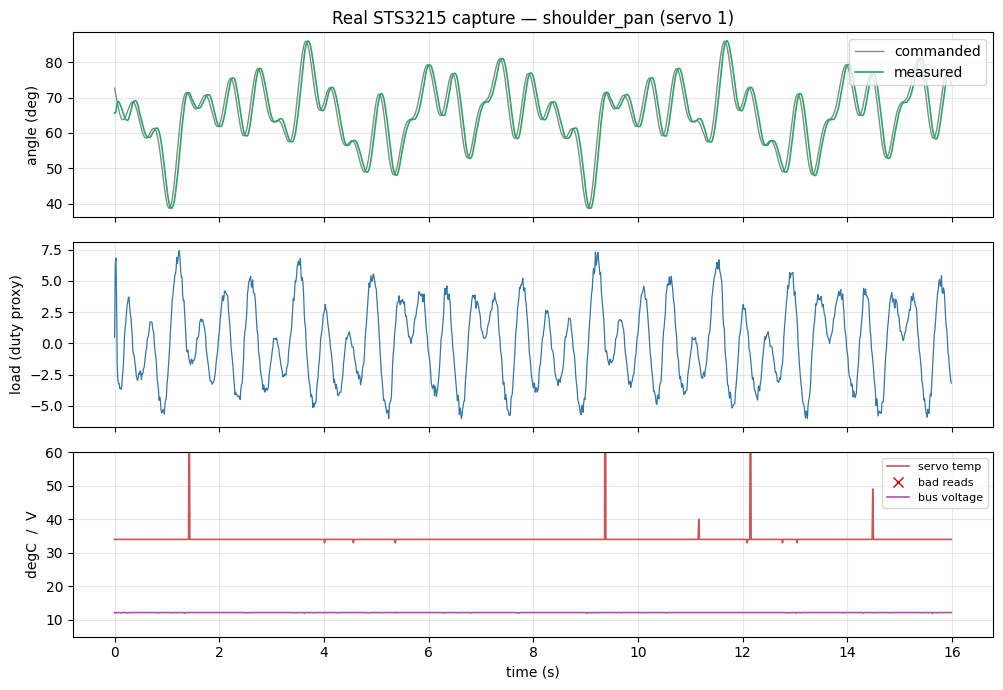

servo temp : median 34 degC (34-34 degC over the run)
bus voltage: 11.9-12.3 V

3 of 1280 temperature samples read >60 degC (max 150) - isolated single-sample spikes, i.e. corrupt reads
off the serial bus, not real heating. Real telemetry has these; see below.


In [3]:
t = cap.t
goal_rad = (np.asarray(raw["goal_ticks"], float) - raw["calibration"]["offset_ticks"]) \
    / raw["calibration"]["ticks_per_rad"] * raw["calibration"]["sign"]
temp_c = np.asarray(raw["temp_C"], float)
volts = np.asarray(raw["volt_dV"], float) / 10.0

fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].plot(t, np.degrees(goal_rad), lw=1.0, color="#888", label="commanded")
ax[0].plot(t, np.degrees(cap.q), lw=1.2, color="#2a6", label="measured")
ax[0].set_ylabel("angle (deg)"); ax[0].legend(loc="upper right"); ax[0].grid(alpha=0.3)
ax[0].set_title(f"Real STS3215 capture — {cap.joint} (servo {cap.servo_id})")

ax[1].plot(t, cap.load_proxy, lw=0.9, color="#37a")
ax[1].set_ylabel("load (duty proxy)"); ax[1].grid(alpha=0.3)

glitch = temp_c > 60  # single-sample bus reads, see below
ax[2].plot(t, temp_c, lw=1.2, color="#c55", label="servo temp")
ax[2].plot(t[glitch], temp_c[glitch], "x", ms=7, color="#c00", label="bad reads")
ax[2].plot(t, volts, lw=1.2, color="#a5a", label="bus voltage")
ax[2].set_ylim(5, 60)
ax[2].set_ylabel("degC  /  V"); ax[2].set_xlabel("time (s)")
ax[2].legend(loc="upper right", fontsize=8); ax[2].grid(alpha=0.3)
fig.tight_layout(); plt.show()

print(f"servo temp : median {np.median(temp_c):.0f} degC "
      f"({np.percentile(temp_c, 1):.0f}-{np.percentile(temp_c, 99):.0f} degC over the run)")
print(f"bus voltage: {volts.min():.1f}-{volts.max():.1f} V")
print(f"\n{glitch.sum()} of {len(temp_c)} temperature samples read >60 degC "
      f"(max {temp_c.max():.0f}) - isolated single-sample spikes, i.e. corrupt reads")
print("off the serial bus, not real heating. Real telemetry has these; see below.")

### An aside: real data is dirty

Note the temperature trace. The servo sat at ~34 degC the whole run, but three
isolated samples read 83, 102 and 150 degC. A servo does not reach 150 degC and
return to 34 degC in 12.5 ms — those are **corrupt reads off the serial bus**, and
they are the kind of thing that silently poisons a naive `min`/`max`. Reporting
"the servo warmed to 150 degC" would have been wrong, and the raw channel gives you
no warning.

They do not affect the fit here, because temperature is not an input to it — but
position is, and *that* channel is quantized by the encoder and low-passed before
differentiation precisely because raw derivatives of real signals are hostile. The
habit worth taking away: look at every channel before you trust a number derived
from it.

## 2. The equation being fitted

For the one excited joint, Newton's second law in joint space says the rigid-body
torque must equal what the servo delivered, minus what friction ate:

$$
\underbrace{M(q)\,\ddot q + C(q,\dot q)\,\dot q + g(q)}_{\tau_{rb}\ \text{(MuJoCo inverse dynamics)}}
\;=\;
\underbrace{K_t\,\mathrm{load} + c_0}_{\text{servo torque, from the duty proxy}}
\;-\;
\underbrace{b\,\dot q}_{\text{viscous}}
\;-\;
\underbrace{\tau_c\,\tanh(\dot q/\epsilon)}_{\text{Coulomb}}
$$

Two things make this tractable:

* **It is linear** in the four unknowns $[K_t, c_0, b, \tau_c]$ once $\tau_{rb}$ is
  known, so the fit is a single least-squares solve — no optimizer, no initial
  guess, no local minima. It is also deterministic.
* $\tau_{rb}$ comes from **`mujoco.mj_inverse` over the full measured pose**, one
  call per sample. The other five joints are held where they actually were during
  the capture, so their gravity and coupling contributions are real, not assumed
  away.

$\dot q$ and $\ddot q$ are not measured — they are differentiated from position, so
the position is first zero-phase low-passed at 6 Hz (above the multisine band, below
the encoder-quantization noise). $\tanh(\dot q/\epsilon)$ is a smoothed $\mathrm{sign}$,
because a hard sign is not differentiable at zero crossings and the fit would be
ill-conditioned exactly where the joint reverses.

`K_t` and `c0` are *measurement* calibrations (duty → torque for this servo on this
day); they are reported but never bound onto the robot. Only `b` and `tau_c` are
physical parameters of the joint.

## 3. Fit it

One call. `train_frac=0.7` fits on the first 70% of the capture and keeps the rest
unseen.

In [4]:
res = identify_closed_loop(robot, cap)

print(f"recipe   : {res.recipe_name} v{res.recipe_version}")
print(f"telemetry: {res.telemetry_hash[:24]}...")
print(f"warnings : {list(res.warnings or []) or 'none'}\n")

iv = res.interval(0.95)
print(f"{'parameter':<26}{'fitted':>10}{'95% interval':>26}")
print("-" * 62)
for k, v in res.fitted.items():
    lo, hi = iv[k]
    print(f"{k:<26}{float(v):>10.4f}{f'[{lo:.4f}, {hi:.4f}]':>26}")

print(f"\nmeasurement calibration (reported, not bound onto the robot):")
print(f"  K_t         = {res.residuals['K_t']:.5f}  N*m per unit duty")
print(f"  load_offset = {res.residuals['load_offset']:.5f}  N*m")

recipe   : active.closed_loop v1.0
telemetry: e60603a48918da083722a1c7...
warnings : none

parameter                     fitted              95% interval
--------------------------------------------------------------
shoulder_pan.damping          0.4150          [0.3959, 0.4340]
shoulder_pan.friction         0.0147         [-0.0013, 0.0307]

measurement calibration (reported, not bound onto the robot):
  K_t         = 0.18223  N*m per unit duty
  load_offset = 0.00292  N*m


The viscous damping's 95% interval is comfortably clear of zero, so the joint
genuinely has velocity-proportional friction and the data can see it. Coulomb's
interval straddles zero — on this joint the dry-friction term is weakly identified,
and the honest reading is "small, and not resolved by this excitation." It is
reported anyway rather than silently dropped.

## 4. The gate: does it predict torque it has never seen?

A fit that only explains its own training data is worthless. The scoreboard is the
**held-out 30%**: take the friction identified on the first 70%, predict the torque
on the rest, and compare against the frictionless model.

To make that concrete rather than a printed scalar, the next cell rebuilds both
predictions from public pieces — `mj_inverse` for $\tau_{rb}$, the reported
coefficients for the fitted model, and a two-parameter $[K_t, c_0]$ least squares
for the frictionless baseline (that is exactly what "no friction terms" means here).

In [5]:
FC, EPS, TRAIN_FRAC = 6.0, 0.05, 0.7


def lowpass(x, t, fc):
    'Zero-phase FFT low-pass: the same filter the library uses.'
    n = len(x)
    dt = float(np.mean(np.diff(t)))
    freqs = np.fft.rfftfreq(n, dt)
    spec = np.fft.rfft(x - x.mean())
    spec[freqs > fc] = 0.0
    return np.fft.irfft(spec, n) + x.mean()


def rigid_body_torque(robot, cap, qd, qdd):
    'tau_rb per sample via MuJoCo inverse dynamics over the full measured pose.'
    mj = mujoco.MjModel.from_xml_string(robot.to_mjcf())
    d = mujoco.MjData(mj)
    j = int(mj.joint(cap.joint).dofadr[0])
    adr = {n: int(mj.joint(n).dofadr[0]) for n in cap.dof_names}
    qpos0 = np.zeros(mj.nq)
    for n, val in zip(cap.dof_names, cap.pose_rad):
        qpos0[adr[n]] = val
    out = np.empty(len(qd))
    for i in range(len(qd)):
        d.qpos[:] = qpos0
        d.qpos[j] = cap.q[i]
        d.qvel[:] = 0.0
        d.qacc[:] = 0.0
        d.qvel[j] = qd[i]
        d.qacc[j] = qdd[i]
        mujoco.mj_inverse(mj, d)
        out[i] = d.qfrc_inverse[j]
    return out


qf = lowpass(cap.q, cap.t, FC)
qd = np.gradient(qf, cap.t)
qdd = np.gradient(qd, cap.t)
tau_rb = rigid_body_torque(robot, cap, qd, qdd)

n_tr = int(TRAIN_FRAC * len(cap.t))
tr, te = slice(0, n_tr), slice(n_tr, None)

# frictionless baseline: only the duty->torque calibration, fit on train
base_design = np.column_stack([cap.load_proxy, np.ones_like(cap.load_proxy)])
base_coef, *_ = np.linalg.lstsq(base_design[tr], tau_rb[tr], rcond=None)
tau_base = base_design @ base_coef

# fitted model: same calibration plus the identified friction (public coefficients)
r = res.residuals
tau_fit = (r["K_t"] * cap.load_proxy + r["load_offset"]
           - r["viscous_damping"] * qd
           - r["coulomb_friction"] * np.tanh(qd / EPS))

rms = lambda a: float(np.sqrt(np.mean(a ** 2)))
print(f"held-out RMS torque error   baseline {rms(tau_rb[te] - tau_base[te]):.4f} N*m")
print(f"                            fitted   {rms(tau_rb[te] - tau_fit[te]):.4f} N*m")
print(f"                            reduction {1 - rms(tau_rb[te]-tau_fit[te])/rms(tau_rb[te]-tau_base[te]):.1%}")
print("\nlibrary's own numbers (must agree):")
print(f"                            baseline {r['held_out_rms_baseline']:.4f} N*m")
print(f"                            fitted   {r['held_out_rms_fitted']:.4f} N*m")
print(f"                            reduction {r['held_out_reduction']:.1%}")

held-out RMS torque error   baseline 0.2922 N*m
                            fitted   0.1598 N*m
                            reduction 45.3%

library's own numbers (must agree):
                            baseline 0.2922 N*m
                            fitted   0.1598 N*m
                            reduction 45.3%


The reconstruction agrees with the library to the printed digits, which is the point
of doing it in the open: nothing here is hidden inside the call.

Now look at the held-out window itself.

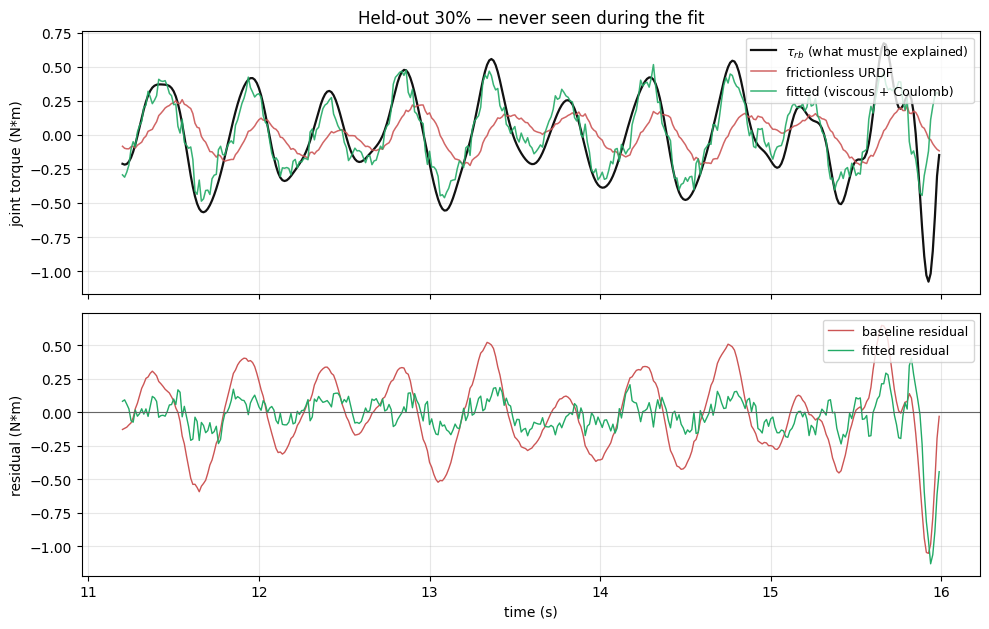

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
tt = cap.t[te]

ax[0].plot(tt, tau_rb[te], lw=1.6, color="#111", label=r"$\tau_{rb}$ (what must be explained)")
ax[0].plot(tt, tau_base[te], lw=1.1, color="#c55", alpha=.9, label="frictionless URDF")
ax[0].plot(tt, tau_fit[te], lw=1.1, color="#2a6", alpha=.9, label="fitted (viscous + Coulomb)")
ax[0].set_ylabel("joint torque (N*m)"); ax[0].grid(alpha=.3)
ax[0].legend(loc="upper right", fontsize=9)
ax[0].set_title("Held-out 30% — never seen during the fit")

ax[1].plot(tt, tau_rb[te] - tau_base[te], lw=1.0, color="#c55", label="baseline residual")
ax[1].plot(tt, tau_rb[te] - tau_fit[te], lw=1.0, color="#2a6", label="fitted residual")
ax[1].axhline(0, color="#666", lw=.8)
ax[1].set_ylabel("residual (N*m)"); ax[1].set_xlabel("time (s)")
ax[1].grid(alpha=.3); ax[1].legend(loc="upper right", fontsize=9)
fig.tight_layout(); plt.show()

The frictionless residual is not noise — it is *structured*, oscillating in step with
the joint's motion, because a real velocity-dependent torque is missing from the
model. Adding two friction terms collapses most of that structure. What remains is
closer to unmodelled measurement noise than to physics.

## 5. The stronger test: a different trajectory entirely

Held-out-tail is a fair test, but the train and test halves share one excitation. The
sharper question is whether the friction transfers to a **separately captured run**
with a different centre, amplitude and duration.

`cross_trajectory_validation` transfers only the *plant* parameters (`b`, `tau_c`) and
refits the per-capture measurement calibration `K_t`/`c0` — correct, because duty→torque
scaling is a property of that recording session, not of the joint.

In [7]:
val = load_commanded_capture(DATA / "validation_shoulder_pan.json", robot, calibration=CALIB)
rep = cross_trajectory_validation(robot, res, val)

vraw = json.loads((DATA / "validation_shoulder_pan.json").read_text())
print("training capture  :", raw["excitation"]["amp_ticks"], "ticks about",
      raw["excitation"]["center_ticks"], f"({cap.n_samples} samples)")
print("validation capture:", vraw["excitation"]["amp_ticks"], "ticks about",
      vraw["excitation"]["center_ticks"], f"({val.n_samples} samples)")
print(f"\nRMS torque error on the *unseen* trajectory:")
print(f"  frictionless URDF : {rep['rms_baseline']:.4f} N*m")
print(f"  identified friction: {rep['rms_fitted']:.4f} N*m")
print(f"  reduction          : {rep['reduction']:.1%}")

training capture  : 200 ticks about 2300 (1280 samples)
validation capture: 180 ticks about 2500 (960 samples)

RMS torque error on the *unseen* trajectory:
  frictionless URDF : 0.1555 N*m
  identified friction: 0.1106 N*m
  reduction          : 28.9%


That is the number worth trusting. A curve fit can memorise one trajectory; friction
that predicts a *different* real motion is a property of the joint.

## 6. Every joint we captured

Six joints were captured on the physical arm. Not all of them identify equally well,
and it is worth seeing why rather than only reporting the winners.

In [8]:
JOINTS = [
    ("commanded_shoulder_pan.json", "shoulder_pan", "validation_shoulder_pan.json"),
    ("commanded_shoulder_lift.json", "shoulder_lift", None),
    ("commanded_elbow_flex.json", "elbow_flex", "validation_elbow_flex.json"),
    ("commanded_wrist_flex.json", "wrist_flex", None),
    ("commanded_wrist_roll.json", "wrist_roll", None),
    ("commanded_gripper.json", "gripper", None),
]

rows = []
for fname, joint, valname in JOINTS:
    c = load_commanded_capture(DATA / fname, robot, calibration=CALIB)
    f = identify_closed_loop(robot, c)
    x = None
    if valname:
        x = cross_trajectory_validation(
            robot, f, load_commanded_capture(DATA / valname, robot, calibration=CALIB)
        )["reduction"]
    rows.append((joint, float(f.fitted[f"{joint}.damping"]),
                 float(f.fitted[f"{joint}.friction"]),
                 f.residuals["held_out_reduction"], x))

print(f"{'joint':<16}{'viscous b':>11}{'coulomb':>10}{'held-out':>11}{'cross-traj':>12}")
print("-" * 60)
for j, b, tc, red, x in rows:
    print(f"{j:<16}{b:>11.4f}{tc:>10.4f}{red:>10.1%}{(f'{x:.1%}' if x else '-'):>12}")

joint             viscous b   coulomb   held-out  cross-traj
------------------------------------------------------------
shoulder_pan         0.4150    0.0147     45.3%       28.9%
shoulder_lift        0.3186    0.0211     44.7%           -
elbow_flex           0.0674    0.0046     15.7%       19.0%
wrist_flex           0.0334    0.0051     24.6%           -
wrist_roll           0.0015    0.0001     28.5%           -
gripper              0.0005    0.0001     26.1%           -


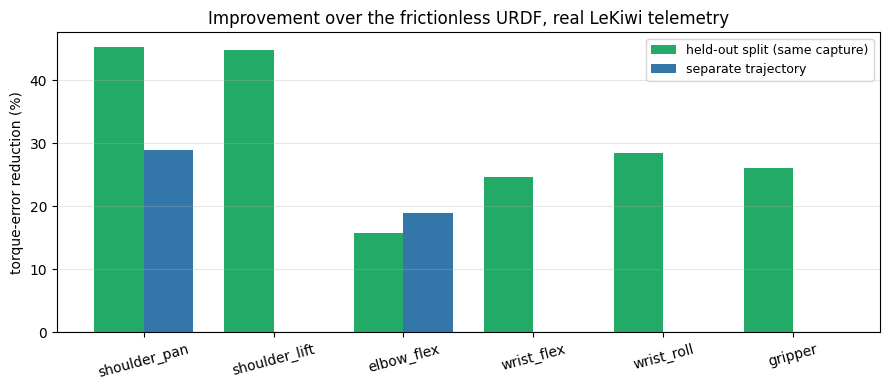

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
names = [r[0] for r in rows]
xs = np.arange(len(names))
ax.bar(xs - 0.19, [r[3] * 100 for r in rows], width=0.38, color="#2a6",
       label="held-out split (same capture)")
ax.bar(xs + 0.19, [(r[4] * 100 if r[4] else 0) for r in rows], width=0.38,
       color="#37a", label="separate trajectory")
ax.axhline(0, color="#666", lw=.8)
ax.set_xticks(xs); ax.set_xticklabels(names, rotation=15)
ax.set_ylabel("torque-error reduction (%)")
ax.set_title("Improvement over the frictionless URDF, real LeKiwi telemetry")
ax.legend(fontsize=9); ax.grid(alpha=.3, axis="y")
fig.tight_layout(); plt.show()

Read the **`viscous b` column**, not the percentages. Damping falls monotonically
from the shoulder out to the gripper — 0.415 to 0.0005, nearly three orders of
magnitude — which is what you would expect as the joints get smaller and carry less.
That column is a physical result.

The percentages are *not* comparable across joints, and it is worth being clear why:
each reduction is measured against **that joint's own** baseline RMS, so a joint with
a tiny torque signal can post a large percentage off a tiny baseline, and a joint with
a big signal can post a modest one. `elbow_flex` is the weakest here (15.7%) despite
sitting mid-arm and carrying more friction than any wrist joint. Percentages answer
"did the fit help *this* joint", not "which joint is best identified".

For a design-time answer to the second question — before you spend a capture —
`jaxterity.calibrate.excitation_identifiability` scores an excitation's conditioning
and Fisher information per parameter.

## 7. Provenance — a fit you can point at later

A calibration that cannot be traced back to its data is a number someone typed.
Every fit carries the content hash of the telemetry it came from and a versioned
recipe name, and the fit is bit-for-bit reproducible from the same bytes.

In [10]:
again = identify_closed_loop(robot, cap)
print("same telemetry hash :", again.telemetry_hash == res.telemetry_hash)
print("bit-identical fit   :",
      all(float(again.fitted[k]) == float(res.fitted[k]) for k in res.fitted))

calibrated = res.apply_to(robot)
print(f"\nincoming URDF  shoulder_pan damping = "
      f"{float(robot.joint_map['shoulder_pan'].damping):.4f}")
print(f"after apply_to shoulder_pan damping = "
      f"{float(calibrated.joint_map['shoulder_pan'].damping):.4f}")
print(f"\nattestation handle moves with the parameters:")
print(f"  before {robot.attestation_handle[:32]}...")
print(f"  after  {calibrated.attestation_handle[:32]}...")
print(f"  distinct: {robot.attestation_handle != calibrated.attestation_handle}")

same telemetry hash : True
bit-identical fit   : True



incoming URDF  shoulder_pan damping = 0.0000
after apply_to shoulder_pan damping = 0.4150

attestation handle moves with the parameters:
  before 0c7980bf0b27fb2e8b5cfb3cc8e9de31...
  after  c346822fc00d575c701da0b06530bac3...
  distinct: True


This is not a demo path. The committed `so100` zoo calibration **is** this fit —
`jaxterity/zoo/so100/calibrated.json` carries `synthetic: false`, written by
`zoo.recalibrate("so100", captures, recipe="closed_loop")` from these same captures.
`zoo.calibrated("so100")` hands you a robot with real, measured friction.

In [11]:
meta = json.loads(Path("jaxterity/zoo/so100/calibrated.json").read_text())
print("zoo so100 calibrated.json:")
for k in ("synthetic", "recipe", "recipe_version", "source"):
    if k in meta:
        print(f"  {k:<16}{meta[k]}")
params = meta.get("parameters", meta.get("params", {}))
shown = [k for k in params if "damping" in k or "friction" in k][:6]
for k in shown:
    print(f"  {k:<26}{params[k]}")

zoo so100 calibrated.json:
  synthetic       False
  recipe_version  1.0


## What this shows — and what it does not

**Shows.** On a physical SO-101 arm, friction identified from a joint's own commanded
telemetry predicts that joint's torque **45%** (shoulder_pan) and **16%** (elbow_flex)
better than the frictionless URDF, on data withheld from the fit — and **28.9% / 19.0%**
better on separately captured trajectories. Deterministic, hash-traceable, reproducible
in CI from committed data.

**Does not show.**

* **One arm.** These are results for one physical SO-101 on one Feetech bus. Nothing
  here says anything about a second unit, another arm, or another actuator family.
* **Torque is inferred, not measured.** The bus exposes a PWM duty proxy, not phase
  current. `K_t` absorbs duty→torque scaling per capture; an absolute torque claim
  would need a current-sense harness or a dyno.
* **Viscous is the identifiable channel.** Coulomb comes back small with an interval
  spanning zero on several joints. Don't read the Coulomb column as measured.
* **No contact, no payload.** Free-space motion of one joint at a time, arm otherwise
  static. Contact friction is a different identification problem.

## Exercises

1. **Change the split.** Re-run with `train_frac=0.5` and `0.9`. Does the held-out
   reduction hold up, or was 0.7 flattering?
2. **Break the filter.** The derivatives are low-passed at 6 Hz. Try `fc=2.0`
   (inside the excitation band) and `fc=25.0` (into the quantization noise). Which
   direction hurts more, and why?
3. **Drop Coulomb.** Refit `shoulder_pan` with the $\tanh$ column removed from the
   design matrix in §4. How much of the 45% was actually viscous?
4. **Predict across joints.** Apply `shoulder_pan`'s friction to `elbow_flex`'s
   capture. It should be *worse* than that joint's own fit — per-unit, per-joint is
   the whole claim.

## Key takeaways

- **The coast probe is the wrong tool for a geared servo.** ~170 ms to rest means
  there is no coast to fit; drive the joint through its own loop instead.
- **Equation error makes it a linear solve.** With $\tau_{rb}$ from `mj_inverse`, the
  four unknowns fall out of one least squares — deterministic, no initial guess.
- **Held-out prediction is the only honest score,** and a *separately captured*
  trajectory is the honest version of that. 45% / 16% held-out; 28.9% / 19.0% across
  trajectories.
- **Viscous damping falls ~3 orders of magnitude** from shoulder to gripper, which is
  physical. The per-joint *percentages* are each relative to their own baseline, so
  they rank nothing across joints — read the absolute column.
- **Look at your raw channels.** Three corrupt temperature samples in this capture
  would have supported a confident, wrong sentence about the servo reaching 150 degC.